In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler


dataset = pd.read_csv('wine.csv')
df = pd.DataFrame(dataset)

display(df.head(6))

X = df.iloc[:, :-1].values  
Y = df.iloc[:, -1].values   


feature_names = df.columns[:-1].tolist()

,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline,Wine
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1
5,14.20,1.76,2.45,15.2,112,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450,1


In [13]:

scaler = StandardScaler()
df_sc = scaler.fit_transform(X)

df_sc_display = pd.DataFrame(df_sc, columns=feature_names)
display(df_sc_display.head(6))

,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874
5,1.481555,-0.517367,0.305159,-1.289707,0.860705,1.562093,1.366128,-0.176095,0.664217,0.731870,0.406051,0.336606,2.239039


In [14]:

pca = PCA(n_components=3)
pca_features = pca.fit_transform(df_sc)

print('Shape before PCA: ', df_sc.shape)
print('Shape after PCA: ', pca_features.shape)

pca_df = pd.DataFrame(
    data=pca_features,
    columns=['PC1', 'PC2', 'PC3']
)

display(pca_df.head(6))

explained_variance = pca.explained_variance_ratio_ 
print(f"Explained Variance Ratios: {explained_variance}")

Shape before PCA:  (178, 13)
Shape after PCA:  (178, 3)


,PC1,PC2,PC3
0,3.316751,1.443463,-0.165739
1,2.209465,-0.333393,-2.026457
2,2.516740,1.031151,0.982819
3,3.757066,2.756372,-0.176192
4,1.008908,0.869831,2.026688
5,3.050254,2.122401,-0.629396


Explained Variance Ratios: [0.36198848 0.1920749  0.11123631]


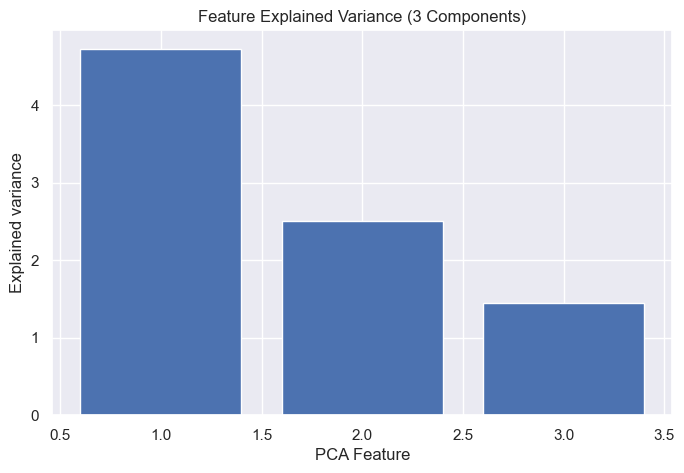

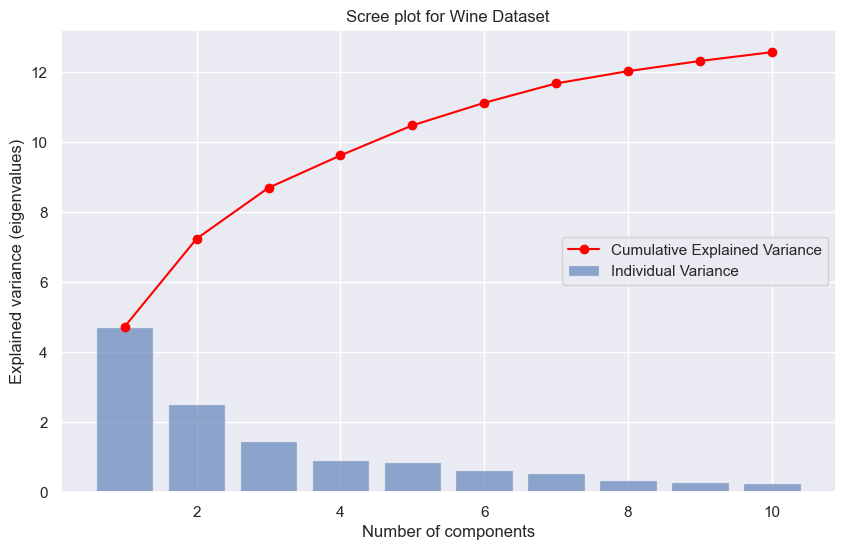

In [15]:
sns.set_theme()

plt.figure(figsize=(8, 5))
plt.bar(
    range(1, len(pca.explained_variance_) + 1),
    pca.explained_variance_
)
plt.xlabel('PCA Feature')
plt.ylabel('Explained variance')
plt.title('Feature Explained Variance (3 Components)')
plt.show()

pca_extended = PCA(n_components=10)
pca_extended.fit(df_sc)

plt.figure(figsize=(10, 6))
plt.bar(
    range(1, len(pca_extended.explained_variance_) + 1),
    pca_extended.explained_variance_,
    alpha=0.6,
    label='Individual Variance'
)
plt.plot(
    range(1, len(pca_extended.explained_variance_) + 1),
    np.cumsum(pca_extended.explained_variance_),
    c='red',
    marker='o',
    label='Cumulative Explained Variance'
)

plt.legend(loc='center right')
plt.xlabel('Number of components')
plt.ylabel('Explained variance (eigenvalues)')
plt.title('Scree plot for Wine Dataset')
plt.show()

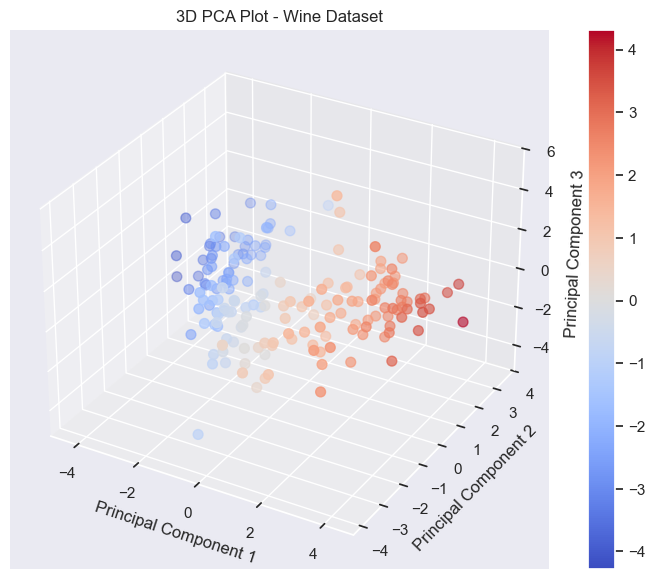

In [16]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(pca_df['PC1'], pca_df['PC2'], pca_df['PC3'], c=pca_df['PC1'], cmap='coolwarm', s=50)

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('3D PCA Plot - Wine Dataset')

plt.colorbar(scatter)
plt.show()

In [17]:

loadings = pca.components_
n_features = pca.n_features_in_ 

pc_list = [f'PC{i}' for i in range(1, n_features + 1)]
pc_loadings = dict(zip(pc_list, loadings))

loadings_df = pd.DataFrame.from_dict(pc_loadings)
loadings_df['feature_names'] = feature_names
loadings_df = loadings_df.set_index('feature_names')

display(loadings_df.head(10))

,PC1,PC2,PC3
feature_names,,,
Alcohol,0.144329,0.483652,-0.207383
Malic.acid,-0.245188,0.224931,0.089013
Ash,-0.002051,0.316069,0.626224
Acl,-0.239320,-0.010591,0.612080
Mg,0.141992,0.299634,0.130757
Phenols,0.394661,0.065040,0.146179
Flavanoids,0.422934,-0.003360,0.150682
Nonflavanoid.phenols,-0.298533,0.028779,0.170368
Proanth,0.313429,0.039302,0.149454


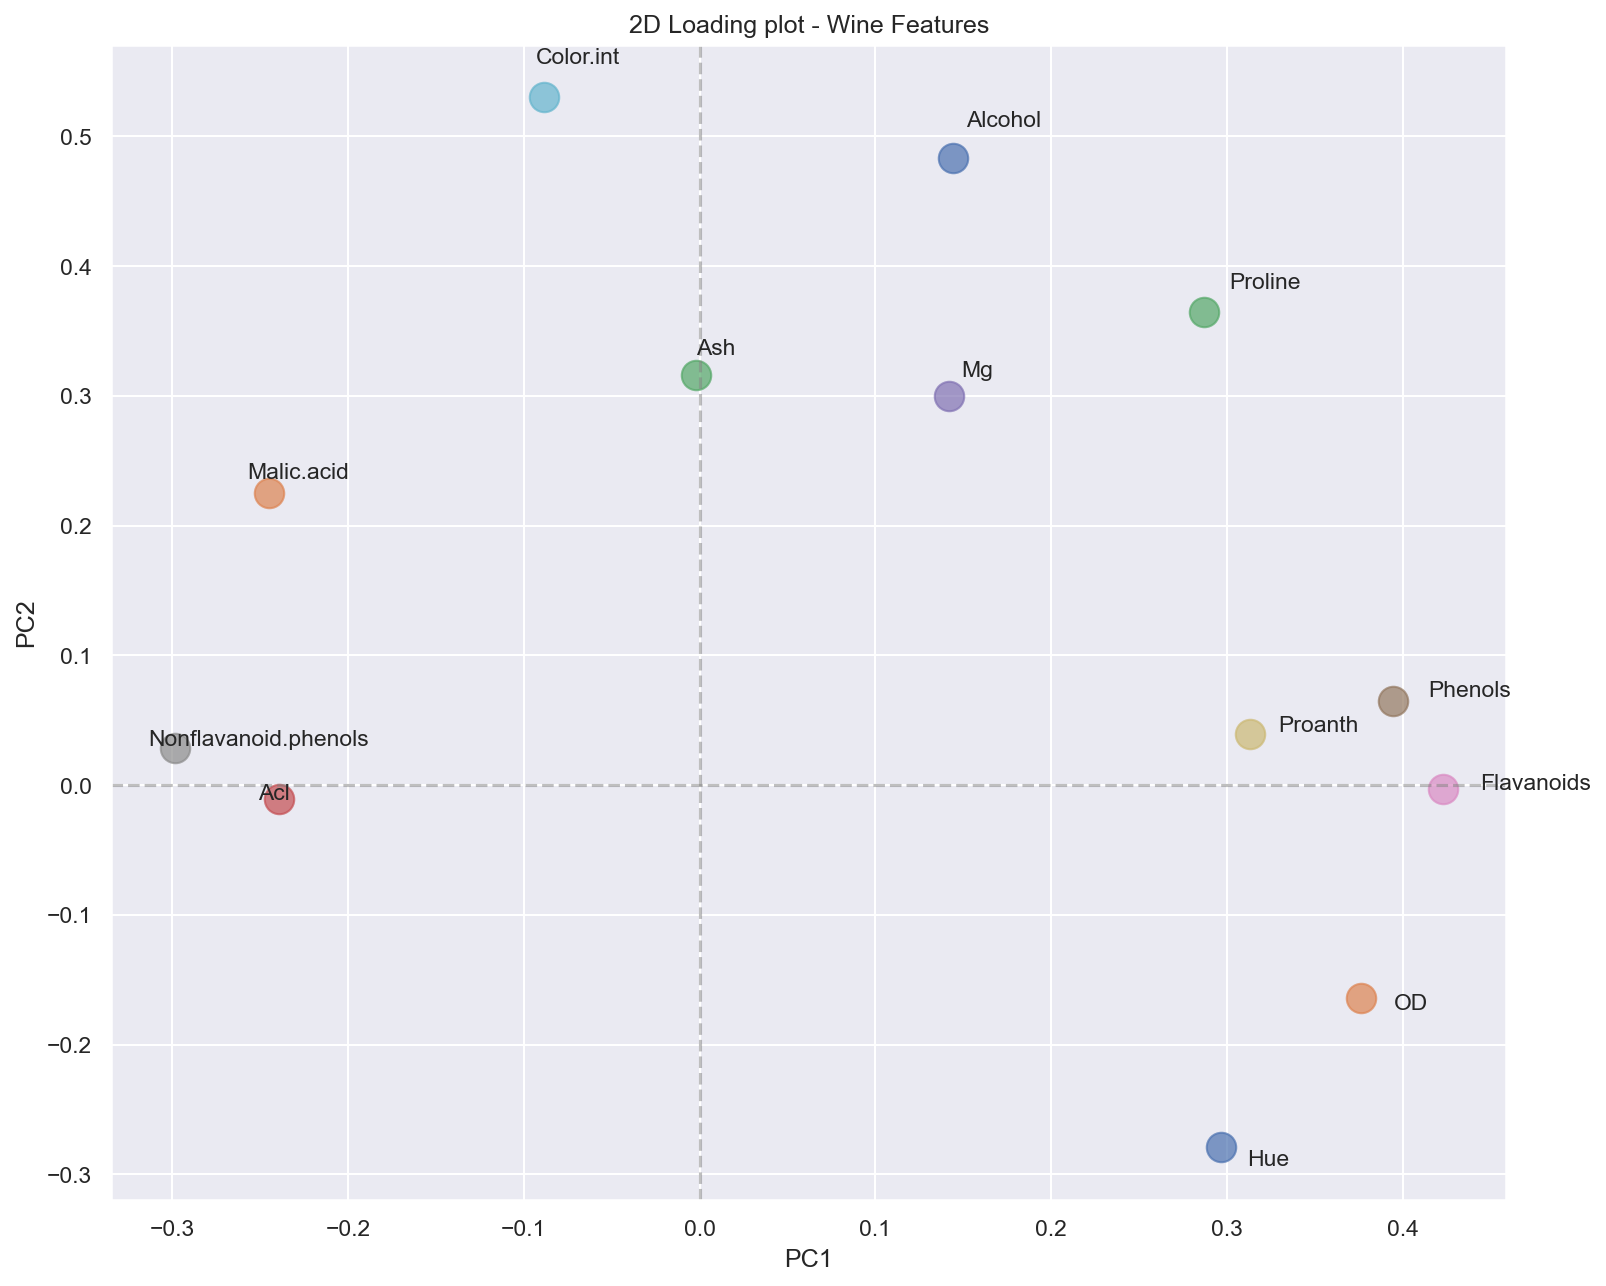

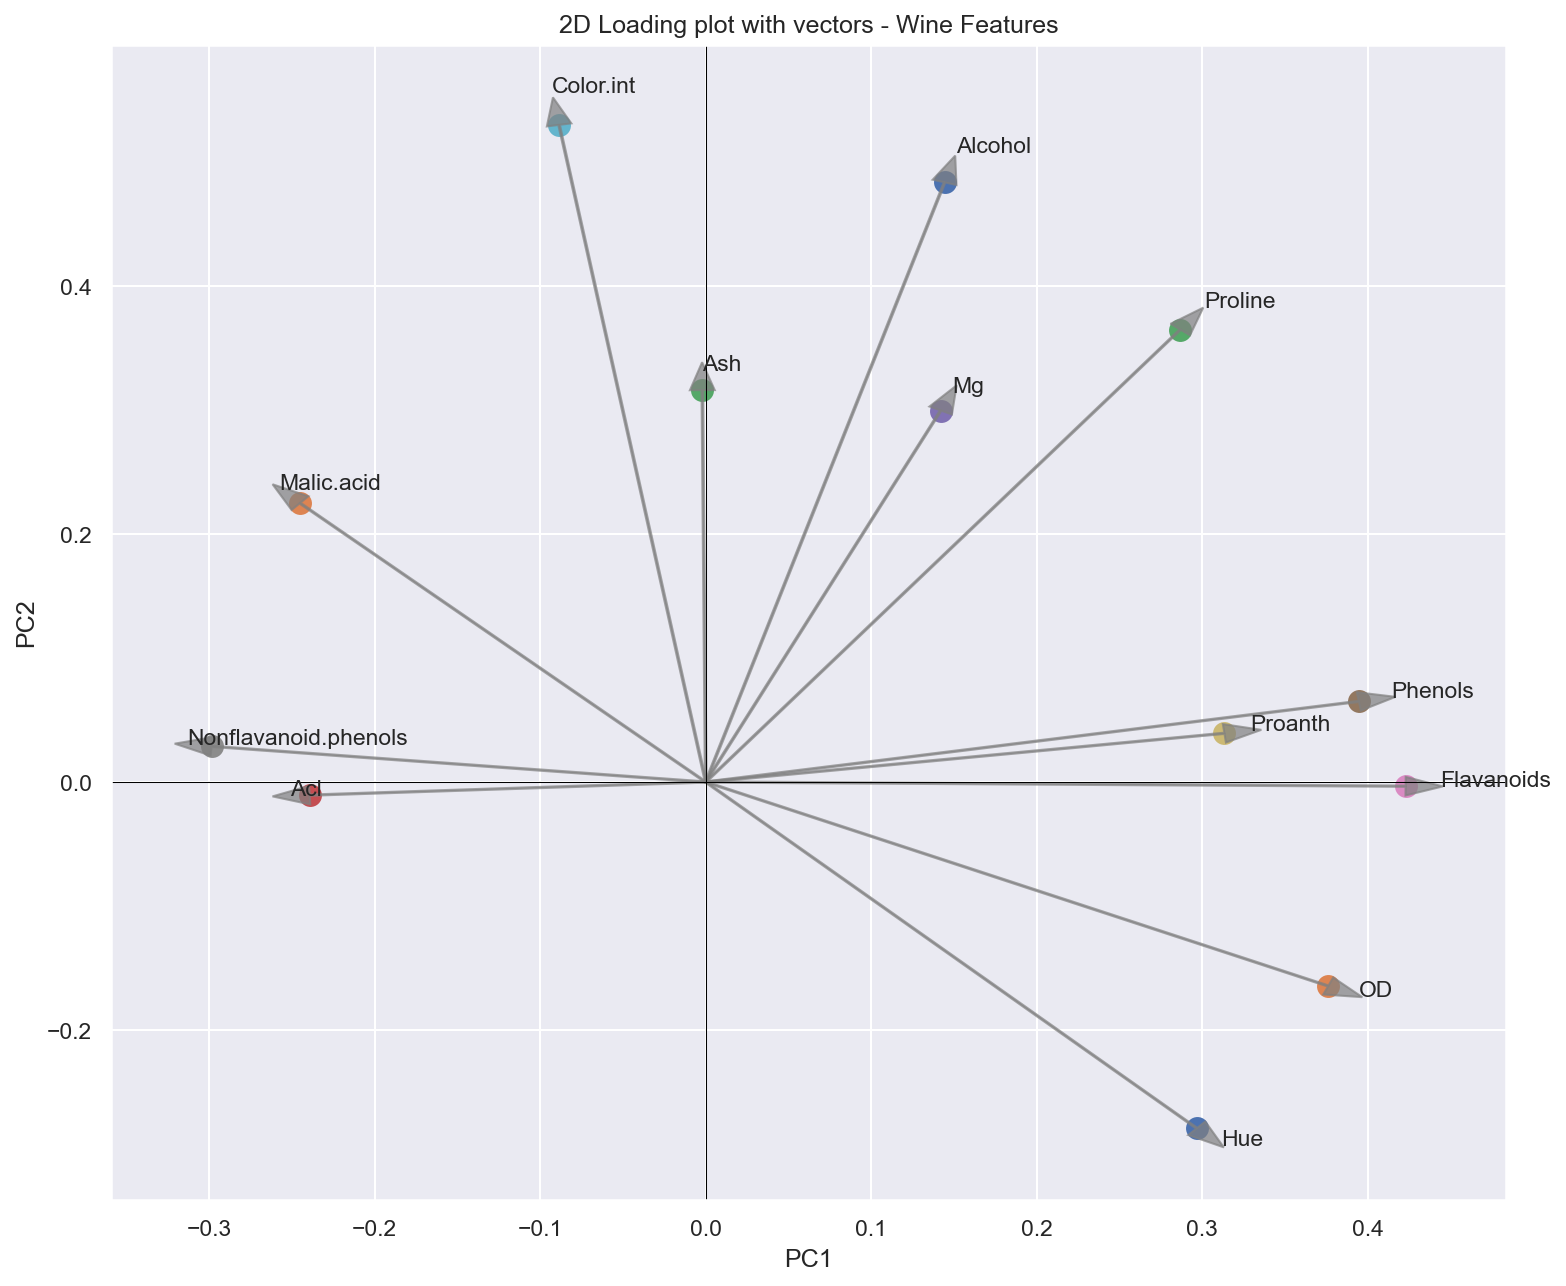

In [18]:
from matplotlib.pyplot import figure

figure(figsize=(12, 10), dpi=150)
xs = loadings[0]
ys = loadings[1]

for i, varnames in enumerate(feature_names):
    plt.scatter(xs[i], ys[i], s=200, alpha=0.7)
    plt.text(xs[i]*1.05, ys[i]*1.05, varnames, fontsize=11)

plt.axhline(0, color='grey', linestyle='--', alpha=0.5)
plt.axvline(0, color='grey', linestyle='--', alpha=0.5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('2D Loading plot - Wine Features')
plt.show()

figure(figsize=(12, 10), dpi=150)

for i, varnames in enumerate(feature_names):
    plt.scatter(xs[i], ys[i], s=100)
    plt.arrow(
        0, 0,
        xs[i], ys[i],
        color='grey',
        linewidth=1,
        head_width=0.015,
        alpha=0.7
    )
    plt.text(xs[i]*1.05, ys[i]*1.05, varnames, fontsize=11)

plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('2D Loading plot with vectors - Wine Features')
plt.show()

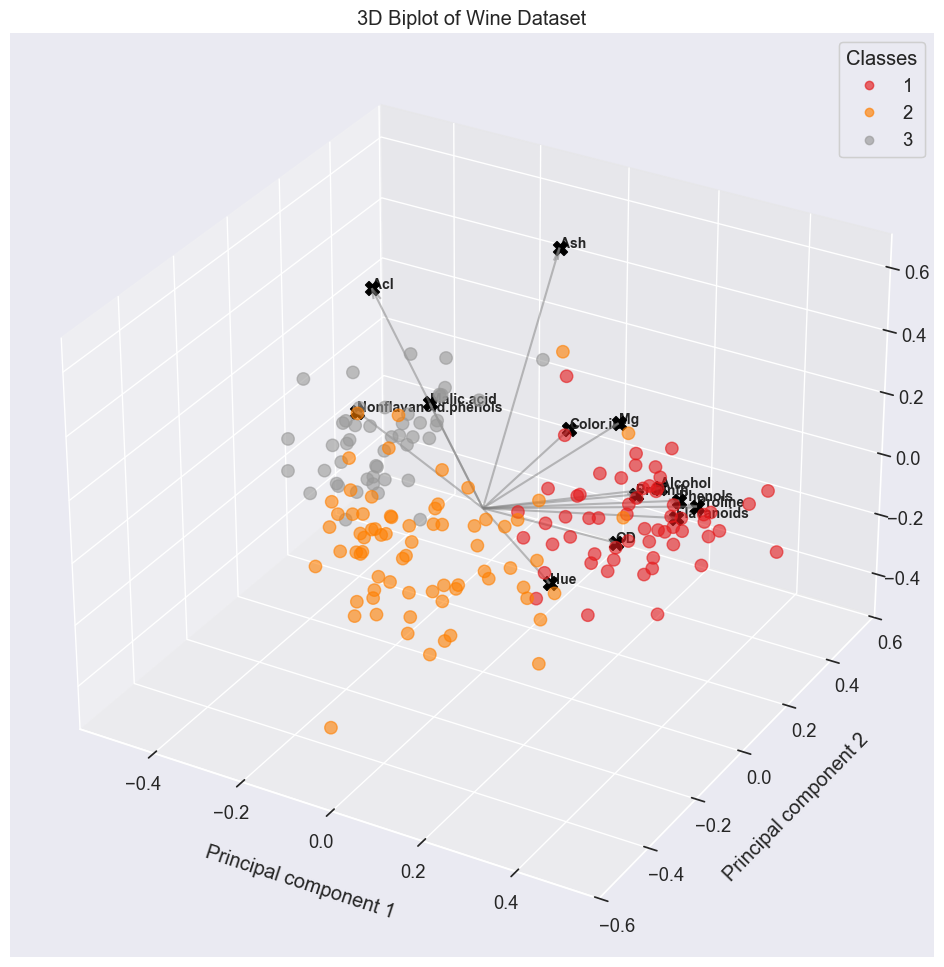

In [19]:
sns.set(font_scale=1.2)

target_names = {
    1: 'Wine Class 1',
    2: 'Wine Class 2',
    3: 'Wine Class 3'
}

pca_df['target'] = Y
pca_df['target_name'] = pca_df['target'].map(target_names)

pca_df_scaled = pca_df.copy()

scaler_df = pca_df[['PC1', 'PC2', 'PC3']]
scaler = 1 / (scaler_df.max() - scaler_df.min())

for index in scaler_df.columns:
    pca_df_scaled[index] *= scaler[index]

fig = plt.figure(figsize=(16, 12))
ax = fig.add_subplot(111, projection='3d')

xdata = pca_df_scaled['PC1']
ydata = pca_df_scaled['PC2']
zdata = pca_df_scaled['PC3']
zs = loadings[2]

scatter3d = ax.scatter3D(
    xdata, ydata, zdata,
    c=Y,
    cmap='Set1',
    s=80,
    alpha=0.6
)

for i, varnames in enumerate(feature_names):
    ax.scatter(xs[i], ys[i], zs[i], s=100, marker='X', color='black')
    ax.text(xs[i], ys[i], zs[i], varnames, fontsize=10, fontweight='bold')

x_arr = np.zeros(len(loadings[0]))
y_arr = z_arr = x_arr

ax.quiver(
    x_arr, y_arr, z_arr, 
    xs, ys, zs, 
    color='grey', alpha=0.5, arrow_length_ratio=0.05
)

plt.title('3D Biplot of Wine Dataset')
ax.set_xlabel('Principal component 1', labelpad=15)
ax.set_ylabel('Principal component 2', labelpad=15)
ax.set_zlabel('Principal component 3', labelpad=15)

legend = ax.legend(*scatter3d.legend_elements(), title="Classes")
ax.add_artist(legend)

plt.show()